In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Titanic EDA Project Started Successfully!")

Matplotlib is building the font cache; this may take a moment.


Titanic EDA Project Started Successfully!


In [2]:
# Load Titanic Dataset

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Titanic Dataset Loaded Successfully!")

df.head()

Titanic Dataset Loaded Successfully!


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# Dataset Information

print("Number of Rows and Columns:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Number of Rows and Columns:
(891, 15)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB

Statistical Summary:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
# Check Missing Values

print("Missing Values in Each Column:")

print(df.isnull().sum())

Missing Values in Each Column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [6]:
# Check Duplicate Records
# Data Cleaning

clean_df = df.copy()

# Fill missing age with median
clean_df['age'] = clean_df['age'].fillna(
    clean_df['age'].median()
)

# Fill missing embarked with mode
clean_df['embarked'] = clean_df['embarked'].fillna(
    clean_df['embarked'].mode()[0]
)

# Fill missing embark_town with mode
clean_df['embark_town'] = clean_df['embark_town'].fillna(
    clean_df['embark_town'].mode()[0]
)

# Remove deck column due to many missing values
clean_df = clean_df.drop(columns=['deck'])

print("Data Cleaning Completed Successfully!")
print("Total Duplicate Rows:")
print(df.duplicated().sum())

Data Cleaning Completed Successfully!
Total Duplicate Rows:
107


In [7]:
print("Missing Values After Cleaning:")

print(clean_df.isnull().sum())

print("\nCleaned Dataset Shape:")
print(clean_df.shape)

Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Cleaned Dataset Shape:
(891, 14)


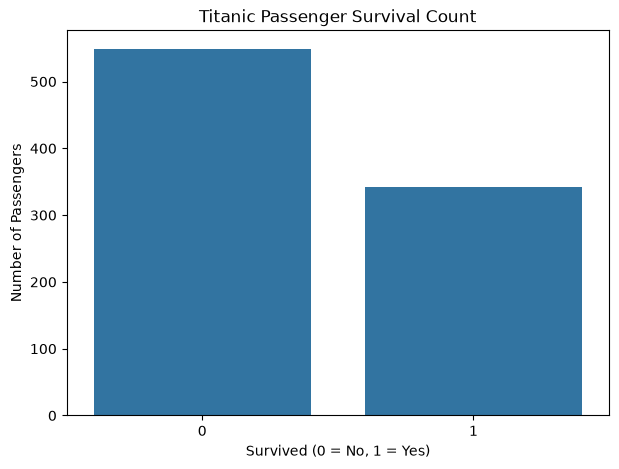

In [8]:
# Survival Count Graph

plt.figure(figsize=(7,5))

sns.countplot(data=clean_df, x='survived')

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

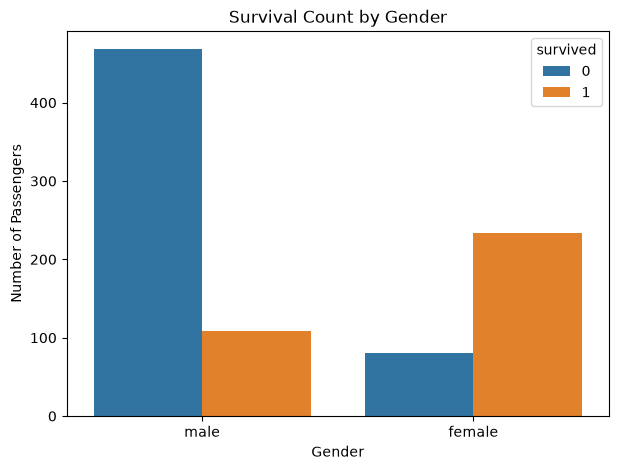

In [9]:
# Gender-wise Survival Graph

plt.figure(figsize=(7,5))

sns.countplot(data=clean_df, x='sex', hue='survived')

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

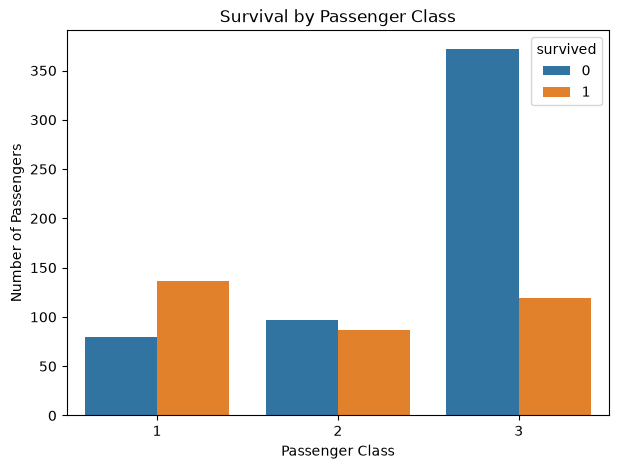

In [10]:
# Survival by Passenger Class

plt.figure(figsize=(7,5))

sns.countplot(data=clean_df, x='pclass', hue='survived')

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

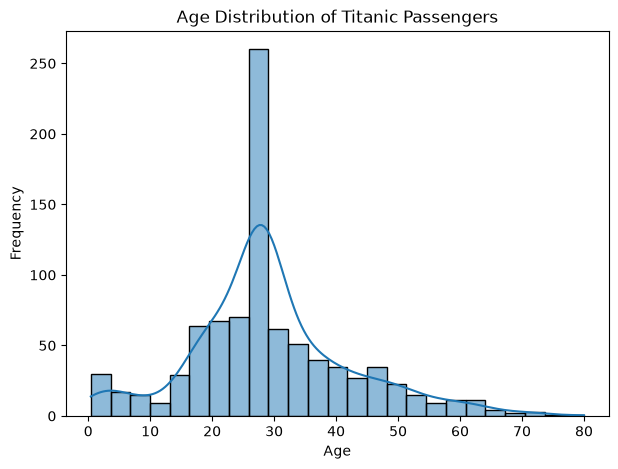

In [11]:
# Age Distribution

plt.figure(figsize=(7,5))

sns.histplot(data=clean_df, x='age', bins=25, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

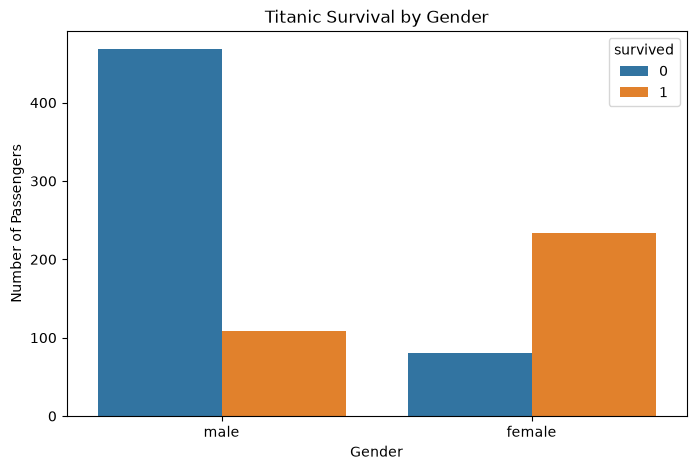

In [12]:
# Gender-wise Survival Analysis

plt.figure(figsize=(8,5))

sns.countplot(data=clean_df, x='sex', hue='survived')

plt.title("Titanic Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

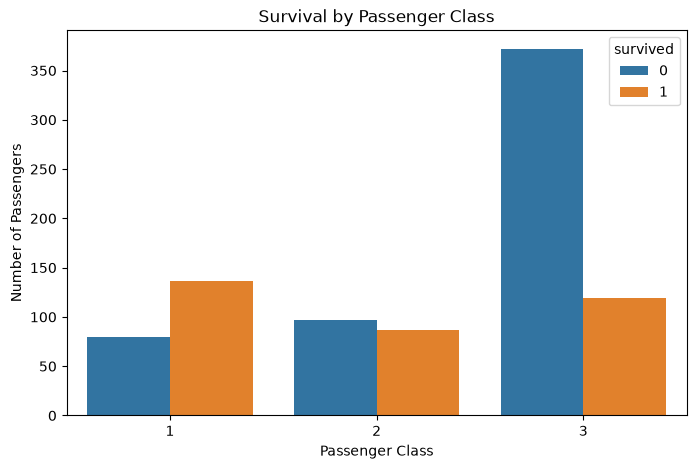

In [13]:
# Survival by Passenger Class

plt.figure(figsize=(8,5))

sns.countplot(data=clean_df, x='pclass', hue='survived')

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

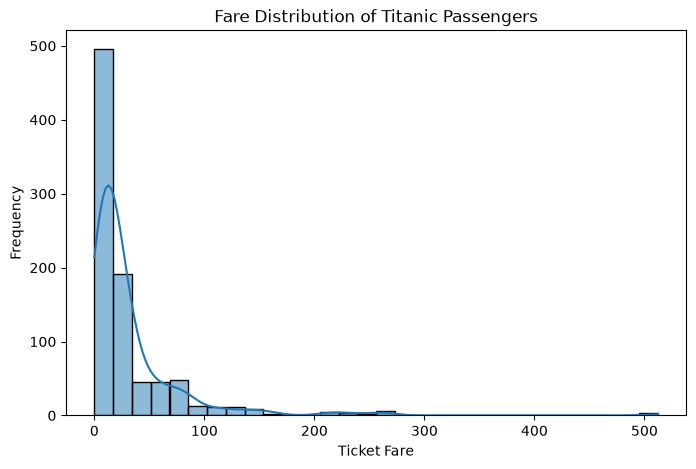

In [14]:
# Fare Distribution

plt.figure(figsize=(8,5))

sns.histplot(data=clean_df, x='fare', bins=30, kde=True)

plt.title("Fare Distribution of Titanic Passengers")
plt.xlabel("Ticket Fare")
plt.ylabel("Frequency")

plt.show()

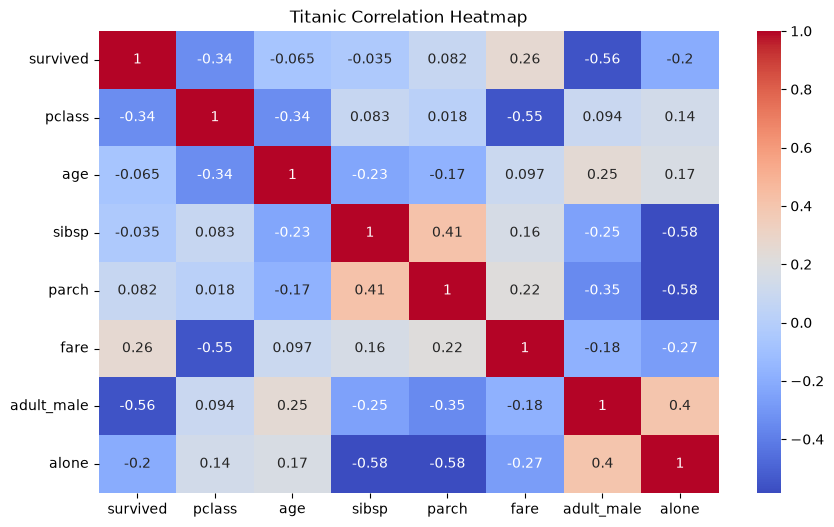

In [15]:
# Correlation Heatmap

plt.figure(figsize=(10,6))

sns.heatmap(clean_df.corr(numeric_only=True),
            annot=True, cmap='coolwarm')

plt.title("Titanic Correlation Heatmap")

plt.show()

In [16]:
# Three Important Findings

print("1. Overall Survival Rate:")

print(clean_df['survived'].mean() * 100, "%")

print("\n2. Gender-wise Survival Rate:")

print(clean_df.groupby('sex')['survived'].mean() * 100)

print("\n3. Passenger Class-wise Survival Rate:")

print(clean_df.groupby('pclass')['survived'].mean() * 100)

1. Overall Survival Rate:
38.38383838383838 %

2. Gender-wise Survival Rate:
sex
female    74.203822
male      18.890815
Name: survived, dtype: float64

3. Passenger Class-wise Survival Rate:
pclass
1    62.962963
2    47.282609
3    24.236253
Name: survived, dtype: float64



# THREE IMPORTANT FINDINGS

### 1. Overall Survival Rate
The overall survival rate of Titanic passengers was 38.38%.

### 2. Gender-wise Survival Rate
- Female survival rate: 74.20%
- Male survival rate: 18.89%

Female passengers had a higher survival rate than male passengers.

### 3. Passenger Class-wise Survival Rate
- First Class: 62.96%
- Second Class: 47.28%
- Third Class: 24.24%

First-class passengers had the highest survival rate.
